# 实验报告 02：NumPy、SciPy、Matplotlib 与 pandas 数据处理

In [1]:
import os
import uuid
import hashlib
import platform

import numpy as np
import scipy
import matplotlib
import matplotlib.pyplot as plt
import pandas as pd

# 修改为自己的学号
STUDENT_ID = 20244080118

CONDA_ENV = os.environ.get("CONDA_DEFAULT_ENV", "base")
print(f"[Conda 环境] {CONDA_ENV}")

MACHINE_FP = hashlib.sha256(
    f"{platform.node()}|{platform.machine()}|{platform.system()}|{uuid.getnode()}".encode()
).hexdigest()[:16]
RUN_ID = f"{STUDENT_ID}-{MACHINE_FP}"
print(f"[学号]        {STUDENT_ID}")
print(f"[机器指纹] {MACHINE_FP}")
print(f"[RUN_ID]   {RUN_ID}")

print(f"[NumPy]      {np.__version__}")
print(f"[SciPy]      {scipy.__version__}")
print(f"[Matplotlib] {matplotlib.__version__}")
print(f"[pandas]     {pd.__version__}")


[Conda 环境] ML
[学号]        20244080118
[机器指纹] 1b75abd9d014d8ea
[RUN_ID]   20244080118-1b75abd9d014d8ea
[NumPy]      2.2.5
[SciPy]      1.15.3
[Matplotlib] 3.10.8
[pandas]     2.3.3


## 实验 1：NumPy 数组、数据类型与索引

先比较三类数组的元数据，再练习变形、布尔索引和两种乘法。

In [2]:
# 1. 整数、浮点数和布尔值数组
int_array = np.array([1, 2, 3, 4], dtype=np.int64)
float_array = np.array([1.5, 2.5, 3.5], dtype=np.float64)
bool_array = np.array([True, False, True, True], dtype=np.bool_)

for name, array in [("整数", int_array), ("浮点数", float_array), ("布尔值", bool_array)]:
    print(f"{name}数组：{array}")
    print(f"  dtype={array.dtype}, shape={array.shape}, ndim={array.ndim}")

print("\n区别：Python 列表中的元素可以是不同类型；ndarray 通常使用统一的 dtype。")
print("这使得 ndarray 的存储更紧凑，也能对整组元素进行向量化运算。")


整数数组：[1 2 3 4]
  dtype=int64, shape=(4,), ndim=1
浮点数数组：[1.5 2.5 3.5]
  dtype=float64, shape=(3,), ndim=1
布尔值数组：[ True False  True  True]
  dtype=bool, shape=(4,), ndim=1

区别：Python 列表中的元素可以是不同类型；ndarray 通常使用统一的 dtype。
这使得 ndarray 的存储更紧凑，也能对整组元素进行向量化运算。


In [3]:
# 2. 改变数组形状
base = np.arange(12)
matrix_3x4 = base.reshape(3, 4)
array_2x3x2 = base.reshape(2, 3, 2)

print("原始数组：")
print(base)
print("\n形状 (3, 4)：")
print(matrix_3x4)
print("\n形状 (2, 3, 2)：")
print(array_2x3x2)


原始数组：
[ 0  1  2  3  4  5  6  7  8  9 10 11]

形状 (3, 4)：
[[ 0  1  2  3]
 [ 4  5  6  7]
 [ 8  9 10 11]]

形状 (2, 3, 2)：
[[[ 0  1]
  [ 2  3]
  [ 4  5]]

 [[ 6  7]
  [ 8  9]
  [10 11]]]


In [4]:
# 3. 索引与布尔筛选
row_2 = matrix_3x4[1]
columns_1_to_3 = matrix_3x4[:, :3]
greater_than_6 = matrix_3x4[matrix_3x4 > 6]

print(f"第 2 行：{row_2}，shape={row_2.shape}")
print(f"第 1 至第 3 列：\n{columns_1_to_3}\nshape={columns_1_to_3.shape}")
print(f"大于 6 的元素：{greater_than_6}，shape={greater_than_6.shape}")


第 2 行：[4 5 6 7]，shape=(4,)
第 1 至第 3 列：
[[ 0  1  2]
 [ 4  5  6]
 [ 8  9 10]]
shape=(3, 3)
大于 6 的元素：[ 7  8  9 10 11]，shape=(5,)


In [5]:
# 4. 组合布尔条件
values = np.arange(10)
less_2_or_greater_7 = values[(values < 2) | (values > 7)]
between_3_and_7 = values[(values > 3) & (values < 7)]

print(f"小于 2 或大于 7：{less_2_or_greater_7}")
print(f"大于 3 且小于 7：{between_3_and_7}")

# 等价写法
print(f"logical_or 写法：{values[np.logical_or(values < 2, values > 7)]}")
print(f"logical_and 写法：{values[np.logical_and(values > 3, values < 7)]}")


小于 2 或大于 7：[0 1 8 9]
大于 3 且小于 7：[4 5 6]
logical_or 写法：[0 1 8 9]
logical_and 写法：[4 5 6]


组合条件时，每个比较表达式都要加括号，因为 `&` 和 `|` 的优先级高于比较运算符。两个布尔数组只有在形状兼容时才能逐元素组合。

In [6]:
# 5. 逐元素乘法与矩阵乘法
A = np.array([[1, 2], [3, 4]])
B = np.array([[5, 6], [7, 8]])

elementwise_1 = A * B
elementwise_2 = np.multiply(A, B)
matrix_product_1 = A @ B
matrix_product_2 = np.matmul(A, B)

print("A * B：")
print(elementwise_1)
print("\nnp.multiply(A, B)：")
print(elementwise_2)
print("\nA @ B：")
print(matrix_product_1)
print("\nnp.matmul(A, B)：")
print(matrix_product_2)

assert np.array_equal(elementwise_1, elementwise_2)
assert np.array_equal(matrix_product_1, matrix_product_2)
print("\n两种逐元素乘法结果相同；两种矩阵乘法结果也相同。")


A * B：
[[ 5 12]
 [21 32]]

np.multiply(A, B)：
[[ 5 12]
 [21 32]]

A @ B：
[[19 22]
 [43 50]]

np.matmul(A, B)：
[[19 22]
 [43 50]]

两种逐元素乘法结果相同；两种矩阵乘法结果也相同。


`*` 与 `np.multiply` 对相同位置的元素相乘；`@` 与 `np.matmul` 按线性代数规则计算行与列的内积。两者在本例中产生不同结果。

## 实验 2：随机抽样、统计与缺失值

使用学号 `20244080118` 初始化随机数生成器，保证每次重启内核后结果一致。

In [7]:
# 1. 模拟 1,000 个成绩并统计
rng = np.random.default_rng(20244080118)
raw_scores = rng.normal(loc=70, scale=10, size=1000)
scores = np.clip(raw_scores, 0, 100)

print(f"样本数：{scores.size}")
print(f"最小值：{scores.min():.4f}")
print(f"最大值：{scores.max():.4f}")
print(f"均值：{scores.mean():.4f}")
print(f"标准差：{scores.std():.4f}")
print(f"极差：{np.ptp(scores):.4f}")


样本数：1000
最小值：32.5108
最大值：100.0000
均值：70.2494
标准差：10.2530
极差：67.4892


In [8]:
# 2. 不放回抽样：均匀抽样与按整数大小加权抽样
population = np.arange(1, 11)
uniform_sample = rng.choice(population, size=5, replace=False)
probabilities = population / population.sum()
weighted_sample = rng.choice(population, size=5, replace=False, p=probabilities)

print(f"总体：{population}")
print(f"均匀抽样：{uniform_sample}")
print(f"权重：{probabilities}")
print(f"加权抽样：{weighted_sample}")


总体：[ 1  2  3  4  5  6  7  8  9 10]
均匀抽样：[ 6 10  7  1  4]
权重：[0.01818182 0.03636364 0.05454545 0.07272727 0.09090909 0.10909091
 0.12727273 0.14545455 0.16363636 0.18181818]
加权抽样：[ 2  6 10  9  5]


In [9]:
# 3. 随机排列与原地打乱
original_for_permutation = np.arange(1, 7)
print(f"permutation 前原数组：{original_for_permutation}")
permuted = rng.permutation(original_for_permutation)
print(f"permuted 结果：{permuted}")
print(f"permutation 后原数组：{original_for_permutation}")

original_for_shuffle = np.arange(1, 7)
print(f"\nshuffle 前原数组：{original_for_shuffle}")
rng.shuffle(original_for_shuffle)
print(f"shuffle 后原数组：{original_for_shuffle}")


permutation 前原数组：[1 2 3 4 5 6]
permuted 结果：[1 5 4 3 6 2]
permutation 后原数组：[1 2 3 4 5 6]

shuffle 前原数组：[1 2 3 4 5 6]
shuffle 后原数组：[3 6 1 4 2 5]


In [10]:
# 4. 缺失值对统计的影响
scores_with_nan = scores.copy()
scores_with_nan[[9, 19, 29]] = np.nan  # 第 10、20、30 个元素（从 1 开始计数）

ordinary_mean = np.mean(scores_with_nan)
missing_aware_mean = np.nanmean(scores_with_nan)
missing_count = np.isnan(scores_with_nan).sum()

print(f"普通均值：{ordinary_mean}")
print(f"忽略缺失值后的均值：{missing_aware_mean:.4f}")
print(f"缺失值个数：{missing_count}")


普通均值：nan
忽略缺失值后的均值：70.2375
缺失值个数：3


In [11]:
# 5. 在内存中整理含缺失值的成绩表，供实验 4 直接使用
scores_df = pd.DataFrame({
    "序号": np.arange(1, scores_with_nan.size + 1),
    "成绩": scores_with_nan,
})

print(f"scores_df 形状：{scores_df.shape}")
display(scores_df.head(10))
print("该表仅保存在当前内核内存中，没有写入磁盘。")


scores_df 形状：(1000, 2)


,序号,成绩
0,1,65.968362
1,2,86.760359
2,3,77.650161
3,4,69.469880
4,5,71.094122
5,6,79.084188
6,7,70.030734
7,8,48.646393
8,9,84.201095
9,10,NaN


该表仅保存在当前内核内存中，没有写入磁盘。


## 实验 3：SciPy 数值计算与 Matplotlib 可视化

In [12]:
# 1. 解线性方程组并回代验证
from scipy.linalg import solve

A_linear = np.array([[3.0, 1.0], [1.0, 2.0]])
b_linear = np.array([9.0, 8.0])
solution = solve(A_linear, b_linear)
verification = A_linear @ solution

print(f"解：x={solution[0]:.4f}, y={solution[1]:.4f}")
print(f"A @ solution = {verification}")
print(f"与右端项一致：{np.allclose(verification, b_linear)}")


解：x=2.0000, y=3.0000
A @ solution = [9. 8.]
与右端项一致：True


In [13]:
# 2. 用 root 求 x^2 - 2 = 0 的正根和负根
from scipy.optimize import root

def equation(x):
    return x**2 - 2

positive_root = root(equation, x0=1.0)
negative_root = root(equation, x0=-1.0)

for label, result in [("正根", positive_root), ("负根", negative_root)]:
    print(f"{label}：success={result.success}, x={result.x[0]:.6f}, f(x)={equation(result.x[0]):.3e}")

print(f"理论值 ±sqrt(2) = ±{np.sqrt(2):.6f}")


正根：success=True, x=1.414214, f(x)=-8.882e-16
负根：success=True, x=-1.414214, f(x)=-8.882e-16
理论值 ±sqrt(2) = ±1.414214


In [14]:
# 3. 求二次函数最小值
from scipy.optimize import minimize

def quadratic(x):
    return x[0]**2 + x[0] + 2

minimum = minimize(quadratic, x0=np.array([0.0]))
x_min = minimum.x[0]
f_min = quadratic(minimum.x)

print(f"success={minimum.success}")
print(f"数值极小点：x={x_min:.6f}, f(x)={f_min:.6f}")
print("解析极小点：x=-0.5, f(x)=1.75")


success=True
数值极小点：x=-0.500000, f(x)=1.750000
解析极小点：x=-0.5, f(x)=1.75


`f(x)=x²+x+2` 的导数为 `2x+1`，令导数为零得到 `x=-0.5`，对应最小值为 `1.75`。SciPy 的数值结果与解析结果一致。

In [15]:
# 4. 独立样本 t 检验
from scipy import stats

test_rng = np.random.default_rng(20244080118)
sample_1 = test_rng.normal(loc=0, scale=1, size=100)
sample_2 = test_rng.normal(loc=1, scale=1, size=100)
t_statistic, p_value = stats.ttest_ind(sample_1, sample_2, equal_var=True)

print(f"t 统计量：{t_statistic:.6f}")
print(f"p 值：{p_value:.6e}")
if p_value < 0.05:
    print("判断：p < 0.05，拒绝两组均值相等的原假设，差异具有统计显著性。")
else:
    print("判断：p >= 0.05，不能拒绝两组均值相等的原假设。")


t 统计量：-5.481620
p 值：1.273771e-07
判断：p < 0.05，拒绝两组均值相等的原假设，差异具有统计显著性。


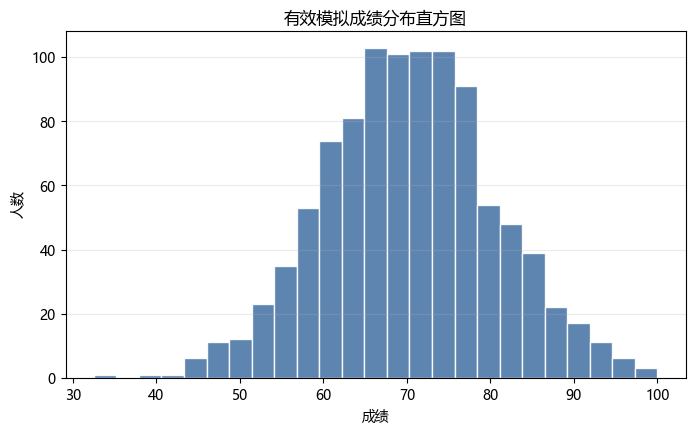

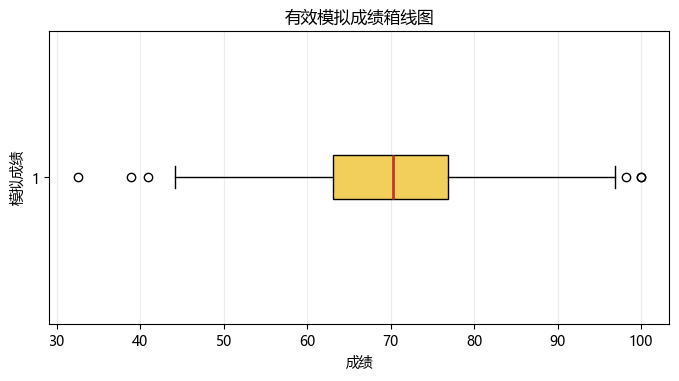

In [16]:
# 5. 有效成绩直方图和箱线图
%matplotlib inline
plt.rcParams["font.sans-serif"] = ["Microsoft YaHei", "SimHei", "DejaVu Sans"]
plt.rcParams["axes.unicode_minus"] = False

valid_scores = scores_with_nan[np.isfinite(scores_with_nan)]

fig, ax = plt.subplots(figsize=(8, 4.5))
ax.hist(valid_scores, bins=25, color="#4C78A8", edgecolor="white", alpha=0.9)
ax.set_title("有效模拟成绩分布直方图")
ax.set_xlabel("成绩")
ax.set_ylabel("人数")
ax.grid(axis="y", alpha=0.25)
plt.show()

fig, ax = plt.subplots(figsize=(8, 3.8))
ax.boxplot(valid_scores, vert=False, patch_artist=True,
           boxprops={"facecolor": "#F2CF5B"},
           medianprops={"color": "#C0392B", "linewidth": 2})
ax.set_title("有效模拟成绩箱线图")
ax.set_xlabel("成绩")
ax.set_ylabel("模拟成绩")
ax.grid(axis="x", alpha=0.25)
plt.show()


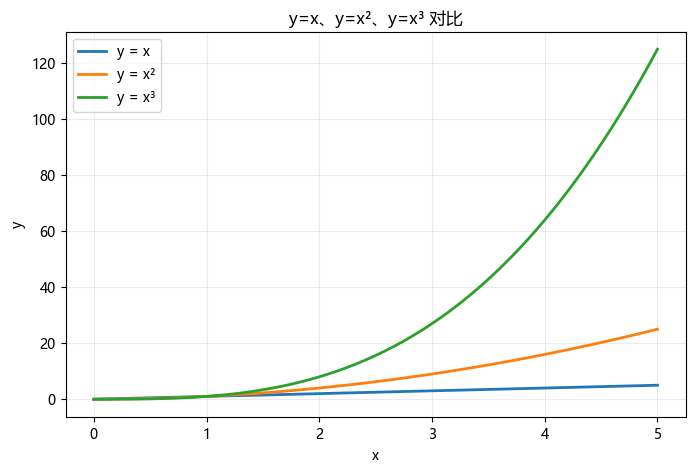

In [17]:
# 5（续）. y=x、y=x^2、y=x^3 折线图
x_values = np.linspace(0, 5, 300)

fig, ax = plt.subplots(figsize=(8, 5))
ax.plot(x_values, x_values, label="y = x", linewidth=2)
ax.plot(x_values, x_values**2, label="y = x²", linewidth=2)
ax.plot(x_values, x_values**3, label="y = x³", linewidth=2)
ax.set_title("y=x、y=x²、y=x³ 对比")
ax.set_xlabel("x")
ax.set_ylabel("y")
ax.legend()
ax.grid(alpha=0.25)
plt.show()


三条曲线在 `x=0` 和 `x=1` 处分别相交；当 `x>1` 时，高次幂增长更快。直方图展示成绩集中位置与分布形状，箱线图突出中位数、四分位范围和离群值。

## 实验 4：pandas Series、DataFrame 与内存中的 CSV 读写

In [18]:
# 验证实验 2 的成绩表仍在内存中，可直接复用
print(f"复用内存表：scores_df.shape={scores_df.shape}, 缺失值={scores_df['成绩'].isna().sum()}")
display(scores_df.tail())


复用内存表：scores_df.shape=(1000, 2), 缺失值=3


,序号,成绩
995,996,72.821317
996,997,74.423407
997,998,79.652407
998,999,59.928461
999,1000,52.122037


In [19]:
# 1. 建立学生成绩 DataFrame
records = {
    "Name": ["Alice", "Bob", "Carol", "David", "Eva", "Frank"],
    "Group": ["A", "A", "B", "B", "A", "B"],
    "Math": [88, 72, 91, 65, 79, 84],
    "English": [90, 68, 85, 73, 92, 77],
    "Python": [95, 80, 89, 70, 86, 82],
}

student_df = pd.DataFrame(records).set_index("Name")
subjects = ["Math", "English", "Python"]
student_df["Total"] = student_df[subjects].sum(axis=1)
student_df["Average"] = student_df[subjects].mean(axis=1)

print(f"行索引：{student_df.index.tolist()}")
print(f"列名：{student_df.columns.tolist()}")
print("\n前 3 行：")
display(student_df.head(3))
print("基本统计信息：")
display(student_df.describe())


行索引：['Alice', 'Bob', 'Carol', 'David', 'Eva', 'Frank']
列名：['Group', 'Math', 'English', 'Python', 'Total', 'Average']

前 3 行：


,Group,Math,English,Python,Total,Average
Name,,,,,,
Alice,A,88,90,95,273,91.000000
Bob,A,72,68,80,220,73.333333
Carol,B,91,85,89,265,88.333333


基本统计信息：


,Math,English,Python,Total,Average
count,6.000000,6.000000,6.000000,6.000000,6.000000
mean,79.833333,80.833333,83.666667,244.333333,81.444444
std,9.907909,9.662643,8.547904,25.781130,8.593710
min,65.000000,68.000000,70.000000,208.000000,69.333333
25%,73.750000,74.000000,80.500000,225.750000,75.250000
50%,81.500000,81.000000,84.000000,250.000000,83.333333
75%,87.000000,88.750000,88.250000,263.000000,87.666667
max,91.000000,92.000000,95.000000,273.000000,91.000000


In [20]:
# 1（续）. 在内存中完成 CSV 往返，不创建磁盘文件
from io import StringIO

csv_buffer = StringIO()
student_df.to_csv(csv_buffer)
csv_buffer.seek(0)
student_df_from_memory = pd.read_csv(csv_buffer, index_col=0)

print(f"内存 CSV 字符数：{len(csv_buffer.getvalue())}")
print(f"读回后的形状：{student_df_from_memory.shape}")
display(student_df_from_memory.head(3))


内存 CSV 字符数：256
读回后的形状：(6, 6)


,Group,Math,English,Python,Total,Average
Name,,,,,,
Alice,A,88,90,95,273,91.000000
Bob,A,72,68,80,220,73.333333
Carol,B,91,85,89,265,88.333333


In [21]:
# 2. loc 与 iloc 读取 Carol，并筛选平均分不低于 80 的学生
carol_by_loc = student_df.loc["Carol"]
carol_position = student_df.index.get_loc("Carol")
carol_by_iloc = student_df.iloc[carol_position]
high_average = student_df[student_df["Average"] >= 80]

print("loc 读取 Carol：")
display(carol_by_loc)
print("iloc 读取 Carol：")
display(carol_by_iloc)
print("平均分不低于 80 的学生：")
display(high_average)


loc 读取 Carol：


Group              B
Math              91
English           85
Python            89
Total            265
Average    88.333333
Name: Carol, dtype: object

iloc 读取 Carol：


Group              B
Math              91
English           85
Python            89
Total            265
Average    88.333333
Name: Carol, dtype: object

平均分不低于 80 的学生：


,Group,Math,English,Python,Total,Average
Name,,,,,,
Alice,A,88,90,95,273,91.000000
Carol,B,91,85,89,265,88.333333
Eva,A,79,92,86,257,85.666667
Frank,B,84,77,82,243,81.000000


In [22]:
# 3. 列均值与行均值
column_means = student_df[subjects].mean(axis=0)
row_means = student_df[subjects].mean(axis=1)

print("三科列均值：")
display(column_means)
print("每名学生的行均值：")
display(row_means.rename("RowMean"))


三科列均值：


Math       79.833333
English    80.833333
Python     83.666667
dtype: float64

每名学生的行均值：


Name
Alice    91.000000
Bob      73.333333
Carol    88.333333
David    69.333333
Eva      85.666667
Frank    81.000000
Name: RowMean, dtype: float64

In [23]:
# 4. apply、agg 和 rank
highest_score = student_df[subjects].apply(lambda row: row.max(), axis=1)
subject_aggregates = student_df[subjects].agg(["min", "mean", "max"])
math_rank = student_df["Math"].rank(method="min", ascending=False).astype(int)

print("每名学生的三科最高分：")
display(highest_score.rename("Highest"))
print("每科最小值、均值和最大值：")
display(subject_aggregates)
print("按数学成绩降序排名：")
display(math_rank.rename("MathRank").to_frame())


每名学生的三科最高分：


Name
Alice    95
Bob      80
Carol    91
David    73
Eva      92
Frank    84
Name: Highest, dtype: int64

每科最小值、均值和最大值：


,Math,English,Python
min,65.000000,68.000000,70.000000
mean,79.833333,80.833333,83.666667
max,91.000000,92.000000,95.000000


按数学成绩降序排名：


,MathRank
Name,
Alice,2
Bob,5
Carol,1
David,6
Eva,4
Frank,3


In [24]:
# 5. 分组统计并广播组内 Python 均值
group_counts = student_df.groupby("Group").size().rename("人数")
group_means = student_df.groupby("Group")[subjects].mean()
student_df["GroupPythonMean"] = student_df.groupby("Group")["Python"].transform("mean")

print("每组人数：")
display(group_counts)
print("每组三科平均分：")
display(group_means)
print("加入所在组 Python 平均分后的完整表：")
display(student_df)


每组人数：


Group
A    3
B    3
Name: 人数, dtype: int64

每组三科平均分：


,Math,English,Python
Group,,,
A,79.666667,83.333333,87.000000
B,80.000000,78.333333,80.333333


加入所在组 Python 平均分后的完整表：


,Group,Math,English,Python,Total,Average,GroupPythonMean
Name,,,,,,,
Alice,A,88,90,95,273,91.000000,87.000000
Bob,A,72,68,80,220,73.333333,87.000000
Carol,B,91,85,89,265,88.333333,80.333333
David,B,65,73,70,208,69.333333,80.333333
Eva,A,79,92,86,257,85.666667,87.000000
Frank,B,84,77,82,243,81.000000,80.333333


In [25]:
# 6. filter 保留 Python 平均分不低于 80 的组
retained_groups = student_df.groupby("Group").filter(
    lambda group: group["Python"].mean() >= 80
)

print("保留组中每组人数：")
display(retained_groups.groupby("Group").size().rename("人数"))
print("保留的组和学生：")
display(retained_groups[subjects + ["GroupPythonMean"]])


保留组中每组人数：


Group
A    3
B    3
Name: 人数, dtype: int64

保留的组和学生：


,Math,English,Python,GroupPythonMean
Name,,,,
Alice,88,90,95,87.000000
Bob,72,68,80,87.000000
Carol,91,85,89,80.333333
David,65,73,70,80.333333
Eva,79,92,86,87.000000
Frank,84,77,82,80.333333


In [26]:
# 7. 协方差矩阵与 Pearson 相关系数矩阵
covariance_matrix = student_df[subjects].cov()
correlation_matrix = student_df[subjects].corr(method="pearson")

print("协方差矩阵：")
display(covariance_matrix)
print("Pearson 相关系数矩阵：")
display(correlation_matrix)


协方差矩阵：


,Math,English,Python
Math,98.166667,62.566667,74.933333
English,62.566667,93.366667,62.533333
Python,74.933333,62.533333,73.066667


Pearson 相关系数矩阵：


,Math,English,Python
Math,1.000000,0.653529,0.884776
English,0.653529,1.000000,0.757105
Python,0.884776,0.757105,1.000000


协方差的符号表示两科成绩变化方向是否一致，正号表示通常同增同减；其数值受成绩单位和离散程度影响。Pearson 相关系数把协方差标准化到 `[-1, 1]`，绝对值越大表示线性关系越强。例如 Math 与 English 的相关系数约为 `0.654`，说明二者存在中等偏强的正线性相关。